In [2]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('/kaggle/input/datasets/andrewmvd/heart-failure-clinical-data/heart_failure_clinical_records_dataset.csv')

# Inspect basic shape and first rows
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
df.head()

Shape: (299, 13)

Missing values:
 age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0



Target Balance:
DEATH_EVENT
0    0.679
1    0.321
Name: proportion, dtype: float64


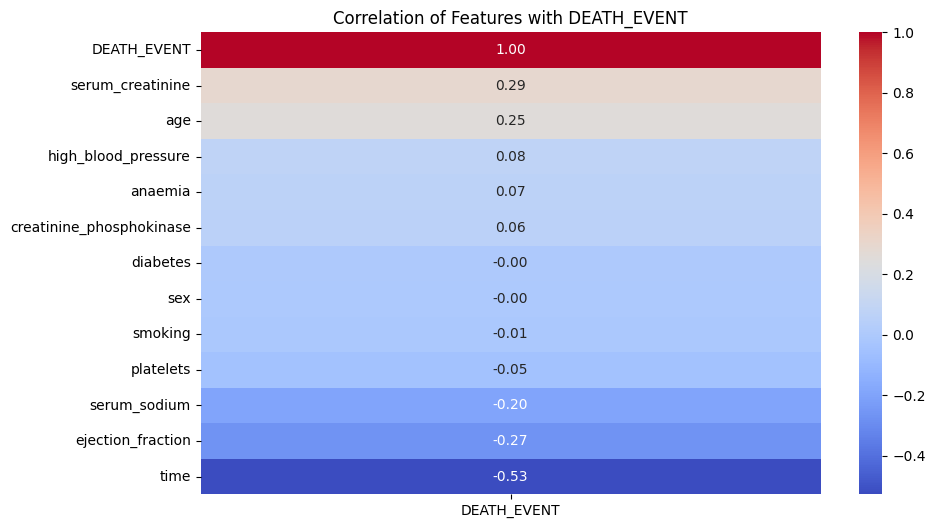

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Statistical summary of features
print("Summary Statistics:")
display(df.describe().T)

# 2. Target distribution (DEATH_EVENT)
print("\nTarget Balance:")
print(df['DEATH_EVENT'].value_counts(normalize=True).round(3))

# 3. Correlation with target
plt.figure(figsize=(10, 6))
corr = df.corr()
sns.heatmap(corr[['DEATH_EVENT']].sort_values(by='DEATH_EVENT', ascending=False), 
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation of Features with DEATH_EVENT")
plt.show()

Data Types & Unique Values:


,dtype,unique_count,has_zero
age,float64,47,0
anaemia,int64,2,170
creatinine_phosphokinase,int64,208,0
diabetes,int64,2,174
ejection_fraction,int64,17,0
high_blood_pressure,int64,2,194
platelets,float64,176,0
serum_creatinine,float64,40,0
serum_sodium,int64,27,0
sex,int64,2,105



Mean values: Survived (0) vs Died (1):


DEATH_EVENT,0,1
age,58.76,65.22
creatinine_phosphokinase,540.05,670.20
ejection_fraction,40.27,33.47
platelets,266657.49,256381.04
serum_creatinine,1.18,1.84
serum_sodium,137.22,135.38


/tmp/ipykernel_49/3204601230.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='DEATH_EVENT', y=col, data=df, palette='Set2')
/tmp/ipykernel_49/3204601230.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='DEATH_EVENT', y=col, data=df, palette='Set2')
/tmp/ipykernel_49/3204601230.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='DEATH_EVENT', y=col, data=df, palette='Set2')
/tmp/ipykernel_49/3204601230.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x

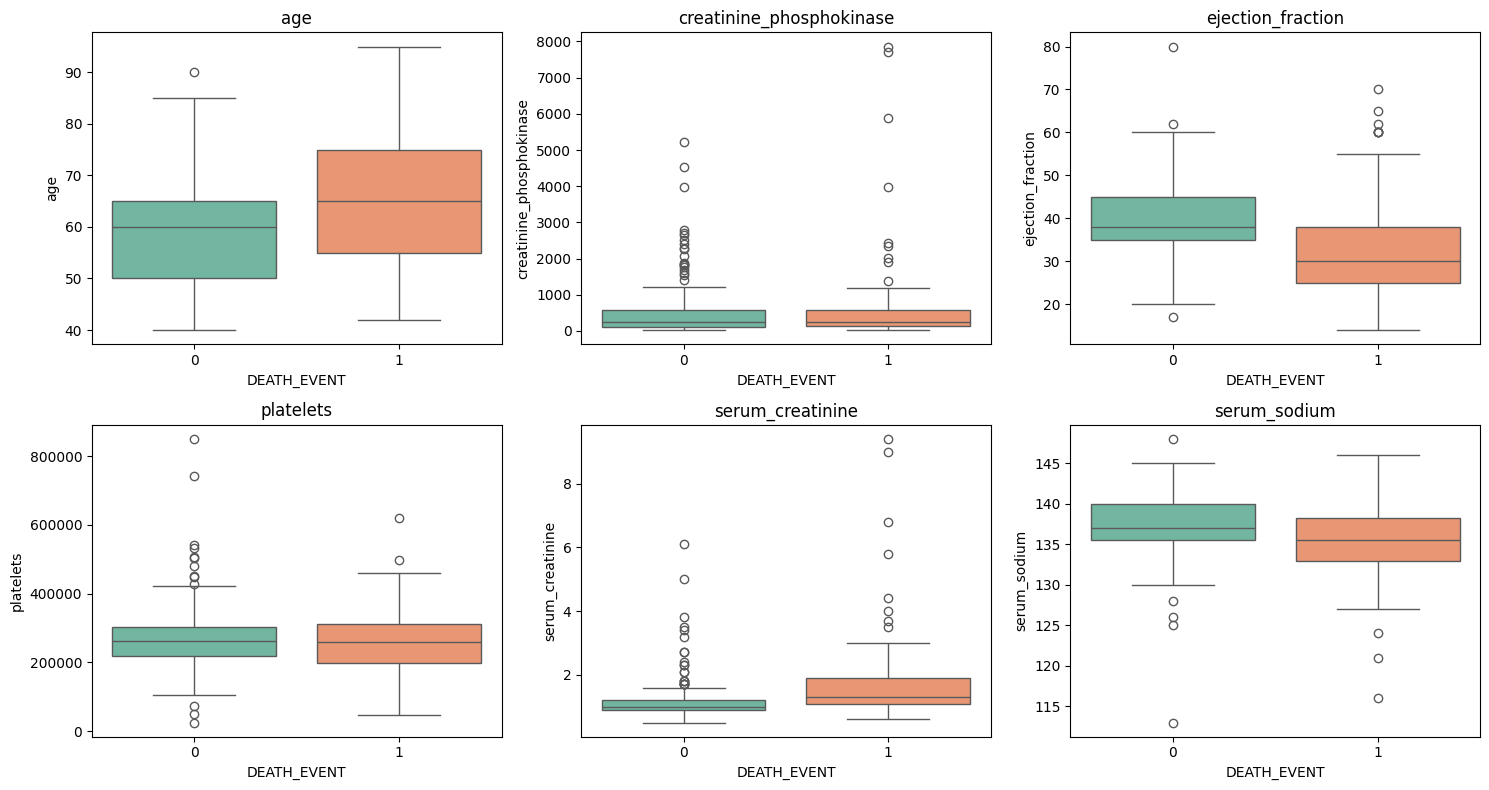

In [4]:
# 1. Check data types and unique values per feature
print("Data Types & Unique Values:")
info_df = pd.DataFrame({
    'dtype': df.dtypes,
    'unique_count': df.nunique(),
    'has_zero': (df == 0).sum()
})
display(info_df)

# 2. Check clinical numerical variables grouped by DEATH_EVENT
num_cols = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 
            'platelets', 'serum_creatinine', 'serum_sodium']

print("\nMean values: Survived (0) vs Died (1):")
display(df.groupby('DEATH_EVENT')[num_cols].mean().round(2).T)

# 3. Visual distributions for the key continuous features
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x='DEATH_EVENT', y=col, data=df, palette='Set2')
    plt.title(col)
plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report
import lightgbm as lgb

# 1. Features & Target
X = df.drop(columns=['DEATH_EVENT', 'time'])
y = df['DEATH_EVENT']

# 2. Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Class weight calculation for imbalance
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# 4. Baseline: Logistic Regression
baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', random_state=42)
)
baseline.fit(X_train, y_train)

# 5. LightGBM Classifier
lgbm = lgb.LGBMClassifier(
    scale_pos_weight=pos_weight,
    random_state=42,
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    verbose=-1
)
lgbm.fit(X_train, y_train)

# 6. Evaluation
for name, model in [("Baseline (Logistic Regression)", baseline), ("LightGBM", lgbm)]:
    probs = model.predict_proba(X_test)[:, 1]
    roc = roc_auc_score(y_test, probs)
    pr = average_precision_score(y_test, probs)
    print(f"=== {name} ===")
    print(f"ROC-AUC: {roc:.3f} | PR-AUC: {pr:.3f}\n")

=== Baseline (Logistic Regression) ===
ROC-AUC: 0.734 | PR-AUC: 0.591

=== LightGBM ===
ROC-AUC: 0.759 | PR-AUC: 0.542



In [6]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss
from sklearn.model_selection import StratifiedKFold

# 1. Wrap LightGBM with Sigmoidal Calibration (Platt Scaling)
calibrated_lgbm = CalibratedClassifierCV(estimator=lgbm, method='sigmoid', cv=3)
calibrated_lgbm.fit(X_train, y_train)

# 2. Evaluate uncalibrated vs calibrated probabilities
raw_probs = lgbm.predict_proba(X_test)[:, 1]
cal_probs = calibrated_lgbm.predict_proba(X_test)[:, 1]

print("=== Brier Score (Lower is Better, Target <= 0.15) ===")
print(f"Raw LightGBM Brier Score:        {brier_score_loss(y_test, raw_probs):.4f}")
print(f"Calibrated LightGBM Brier Score: {brier_score_loss(y_test, cal_probs):.4f}")

print("\n=== Calibrated Metrics on Test Set ===")
print(f"ROC-AUC:  {roc_auc_score(y_test, cal_probs):.3f}")
print(f"PR-AUC:   {average_precision_score(y_test, cal_probs):.3f}")

=== Brier Score (Lower is Better, Target <= 0.15) ===
Raw LightGBM Brier Score:        0.1919
Calibrated LightGBM Brier Score: 0.1862

=== Calibrated Metrics on Test Set ===
ROC-AUC:  0.741
PR-AUC:   0.511


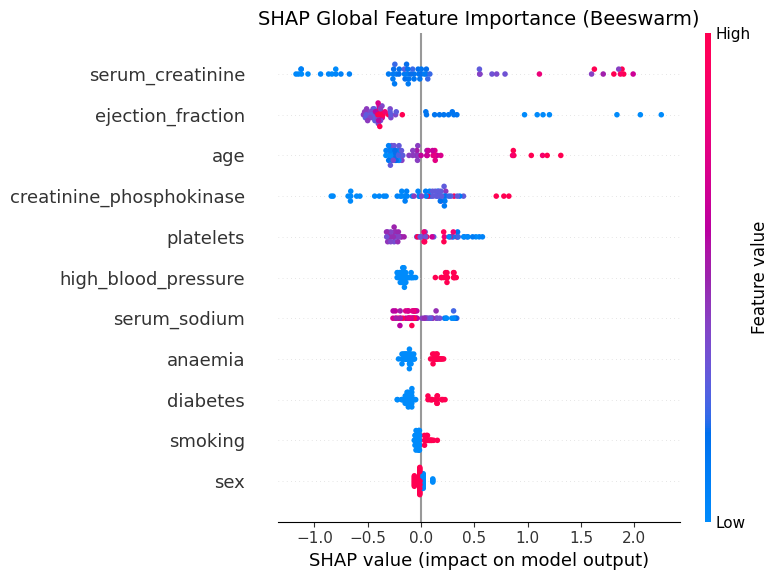

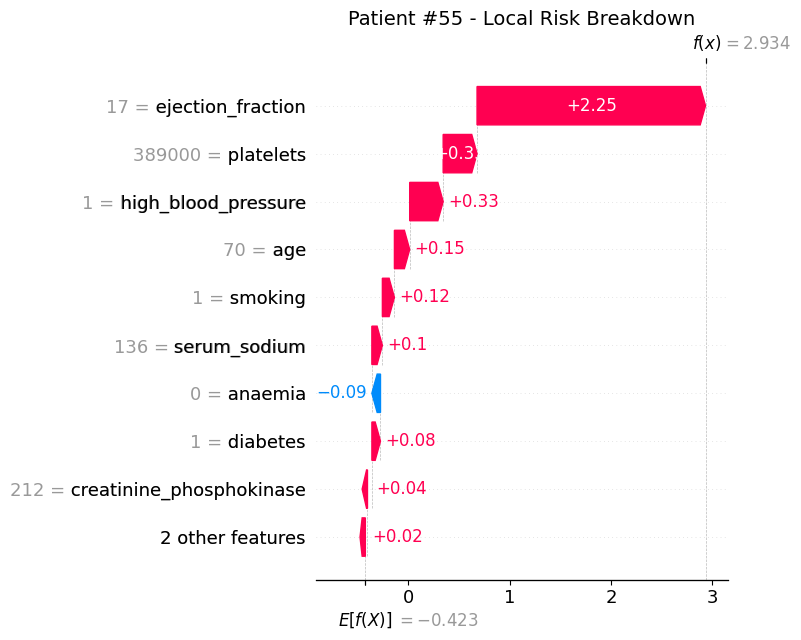

In [7]:
import shap
import matplotlib.pyplot as plt

# 1. Initialize TreeExplainer on the trained LightGBM model
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer(X_test)

# 2. Global Explainability: Beeswarm Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP Global Feature Importance (Beeswarm)", fontsize=14)
plt.tight_layout()
plt.show()

# 3. Local Explainability: Waterfall Plot for a high-risk patient in test set
# Select the patient with the highest predicted probability in the test set
highest_risk_idx = np.argmax(lgbm.predict_proba(X_test)[:, 1])

plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values[highest_risk_idx], show=False)
plt.title(f"Patient #{highest_risk_idx} - Local Risk Breakdown", fontsize=14)
plt.tight_layout()
plt.show()

In [8]:
import joblib

# Save the trained LightGBM model and feature names
model_artifacts = {
    "model": lgbm,
    "features": list(X.columns)
}

joblib.dump(model_artifacts, "clinical_lgbm_model.pkl")
print("Saved model artifacts to 'clinical_lgbm_model.pkl' successfully.")

Saved model artifacts to 'clinical_lgbm_model.pkl' successfully.
